# 01 - Data ingestion (US)

Quatre sources : US Treasury (par yields), FRED (CMT DGS*), FRED (VIX, USREC) et NBER (scraping).
Chaque connecteur tente un pull en ligne, le sauvegarde en JSON dans `data/raw/`, et retombe sur le cache si l'API est indisponible.
Les taux sont en pourcents, les maturités en années.

In [7]:
import io, re
from datetime import date
from pathlib import Path

import pandas as pd
import requests

RAW_DIR = Path("../data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

HEADERS = {"User-Agent": "Mozilla/5.0 (yield-curve-project)"}
START_YEAR = 1990
END_YEAR = 2024

## Cache JSON

In [8]:
def save_json(df, name):
    df.to_json(RAW_DIR / f"{name}.json", orient="records", date_format="iso", indent=2)


def load_json(name):
    df = pd.read_json(RAW_DIR / f"{name}.json", orient="records", convert_dates=False)
    if "date" in df.columns:
        df["date"] = pd.to_datetime(df["date"])
    return df


def fetch_or_cache(name, fetch_fn):
    """Pull en ligne et met en cache ; en cas d'echec, relit le JSON existant."""
    try:
        df = fetch_fn()
        save_json(df, name)
        print(f"[live]  {name}: {len(df):,} lignes")
    except Exception as e:
        if not (RAW_DIR / f"{name}.json").exists():
            raise
        print(f"[cache] {name}: echec en ligne ({e!r}), lecture de {name}.json")
        df = load_json(name)
    return df

## 1. US Treasury - par yield curve (CSV annuels)

In [9]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{y}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={y}&page&_format=csv"
)


def label_to_years(label):
    """'1 Mo' -> 1/12, '1.5 Month' -> 0.125, '10 Yr' -> 10. None si colonne non reconnue."""
    m = re.match(r"\s*([\d.]+)\s*(mo|month|yr|year)", str(label), flags=re.I)
    if not m:
        return None
    n, unit = float(m.group(1)), m.group(2).lower()
    return n / 12 if unit.startswith("mo") else n


def fetch_treasury():
    frames = []
    for y in range(START_YEAR, END_YEAR + 1):
        r = requests.get(TREASURY_URL.format(y=y), headers=HEADERS, timeout=60)
        r.raise_for_status()
        wide = pd.read_csv(io.StringIO(r.text))
        wide["Date"] = pd.to_datetime(wide["Date"], format="%m/%d/%Y")
        frames.append(wide.melt(id_vars="Date", var_name="label", value_name="rate"))
    df = pd.concat(frames, ignore_index=True).rename(columns={"Date": "date"})
    df["maturity"] = df["label"].map(label_to_years)
    df = df.dropna(subset=["maturity", "rate"])
    df["source"] = "treasury"
    return (df[["date", "maturity", "rate", "label", "source"]]
            .sort_values(["date", "maturity"]).reset_index(drop=True))


treasury = fetch_or_cache("treasury_par_yields", fetch_treasury)
treasury.head()

[live]  treasury_par_yields: 93,583 lignes


,date,maturity,rate,label,source
0,1990-01-02,0.25,7.83,3 Mo,treasury
1,1990-01-02,0.50,7.89,6 Mo,treasury
2,1990-01-02,1.00,7.81,1 Yr,treasury
3,1990-01-02,2.00,7.87,2 Yr,treasury
4,1990-01-02,3.00,7.90,3 Yr,treasury


## 2. FRED - Constant Maturity Treasury (DGS1MO a DGS30)

In [10]:
FRED_URL = "https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"

FRED_CURVE = {
    "DGS1MO": 1 / 12, "DGS3MO": 3 / 12, "DGS6MO": 6 / 12,
    "DGS1": 1, "DGS2": 2, "DGS3": 3, "DGS5": 5, "DGS7": 7,
    "DGS10": 10, "DGS20": 20, "DGS30": 30,
}


def fred_series(sid):
    r = requests.get(FRED_URL.format(sid=sid), headers=HEADERS, timeout=60)
    r.raise_for_status()
    s = pd.read_csv(io.StringIO(r.text), na_values=".")
    s.columns = ["date", "value"]          # le nom de la 1re colonne varie (DATE / observation_date)
    s["date"] = pd.to_datetime(s["date"])
    return s.dropna(subset=["value"])


def fetch_fred_curve():
    frames = []
    for sid, mat in FRED_CURVE.items():
        s = fred_series(sid).rename(columns={"value": "rate"})
        s["maturity"], s["series"], s["source"] = mat, sid, "fred"
        frames.append(s)
    df = pd.concat(frames, ignore_index=True)
    return (df[["date", "maturity", "rate", "series", "source"]]
            .sort_values(["date", "maturity"]).reset_index(drop=True))


fred_curve = fetch_or_cache("fred_cmt_yields", fetch_fred_curve)
fred_curve.head()

[live]  fred_cmt_yields: 147,311 lignes


,date,maturity,rate,series,source
0,1962-01-02,1.0,3.22,DGS1,fred
1,1962-01-02,3.0,3.70,DGS3,fred
2,1962-01-02,5.0,3.88,DGS5,fred
3,1962-01-02,10.0,4.06,DGS10,fred
4,1962-01-02,20.0,4.07,DGS20,fred


## 3. FRED - VIX et indicateur de recession USREC

In [11]:
vix = fetch_or_cache("fred_vixcls", lambda: fred_series("VIXCLS"))
usrec = fetch_or_cache("fred_usrec", lambda: fred_series("USREC"))
display(vix.tail(3)); display(usrec.tail(3))

[live]  fred_vixcls: 9,287 lignes
[live]  fred_usrec: 2,062 lignes


,date,value
9586,2026-09-30,16.34
9587,2026-10-01,16.39
9588,2026-10-02,15.31


,date,value
2059,2026-07-01,0
2060,2026-08-01,0
2061,2026-09-01,0


## 4. NBER - dates de reference des cycles (scraping)

In [12]:
import html

NBER_URL = "https://www.nber.org/research/data/us-business-cycle-expansions-and-contractions"
MONTHS = "January|February|March|April|May|June|July|August|September|October|November|December"
NBER_PAT = re.compile(rf"\b({MONTHS})\s+(\d{{4}})\s*\(\s*(?:\d{{4}}\s*Q[1-4]|[IV]+)\s*\)")


def fetch_nber():
    """Scrape les dates pic/creux. Extraction par motif 'Mois AAAA (AAAAQn)' dans le texte de la page,
    independante de la structure HTML du tableau."""
    r = requests.get(NBER_URL, headers=HEADERS, timeout=60)
    r.raise_for_status()
    text = html.unescape(re.sub(r"<[^>]+>", " ", r.text)).replace("\xa0", " ")
    dates = [pd.to_datetime(f"{m} {y}", format="%B %Y") for m, y in NBER_PAT.findall(text)]
    dates = list(dict.fromkeys(dates))        # dedoublonne (table desktop/mobile eventuellement dupliquee)
    # ordre de la page : creux 1854 seul, puis (pic, creux) pour chaque recession
    if len(dates) < 5 or len(dates) % 2 == 0:
        raise ValueError(f"{len(dates)} dates NBER extraites, structure inattendue "
                         "(attendu : nombre impair, la 1re est le creux de decembre 1854)")
    df = pd.DataFrame({"peak": dates[1::2], "trough": dates[2::2]})
    if len(df) < 34:
        print(f"ATTENTION : {len(df)} recessions extraites, 34 attendues sur 1854-2020")
    return df


nber = fetch_or_cache("nber_cycles", fetch_nber)
nber.tail()

[live]  nber_cycles: 34 lignes


,peak,trough
29,1981-07-01,1982-11-01
30,1990-07-01,1991-03-01
31,2001-03-01,2001-11-01
32,2007-12-01,2009-06-01
33,2020-02-01,2020-04-01


## Controles rapides

In [13]:
for name, df in {"treasury": treasury, "fred_curve": fred_curve, "vix": vix, "usrec": usrec}.items():
    print(f"{name:11s} {df['date'].min().date()} -> {df['date'].max().date()}  {len(df):>8,} lignes")

# Validation croisee Treasury vs FRED sur le 10 ans
t10 = treasury.loc[treasury["maturity"] == 10, ["date", "rate"]].set_index("date")["rate"]
f10 = fred_curve.loc[fred_curve["series"] == "DGS10", ["date", "rate"]].set_index("date")["rate"]
both = pd.concat([t10.rename("treasury"), f10.rename("fred")], axis=1)
common = both.dropna()
print(f"\n10Y : {len(common):,} dates communes, ecart absolu max = {(common.treasury - common.fred).abs().max():.4f} pt")
print(f"dates uniquement Treasury : {both.fred.isna().sum()}, uniquement FRED : {both.treasury.isna().sum()}")

# Grille de maturites disponible par decennie (visible : 2m, 4m, 1.5m apparaissent tard)
grid = treasury.assign(decade=(treasury["date"].dt.year // 10) * 10).groupby("decade")["maturity"].unique()
grid.map(lambda a: sorted(round(x, 3) for x in a))

treasury    1990-01-02 -> 2024-12-31    93,583 lignes
fred_curve  1962-01-02 -> 2026-10-02   147,311 lignes
vix         1990-01-02 -> 2026-10-02     9,287 lignes
usrec       1854-12-01 -> 2026-09-01     2,062 lignes

10Y : 8,756 dates communes, ecart absolu max = 0.0000 pt
dates uniquement Treasury : 0, uniquement FRED : 7418


C:\Users\orang\AppData\Local\Temp\ipykernel_3272\2078789402.py:7: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  both = pd.concat([t10.rename("treasury"), f10.rename("fred")], axis=1)


decade
1990    [0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10.0, 20....
2000    [0.083, 0.25, 0.5, 1.0, 2.0, 3.0, 5.0, 7.0, 10...
2010    [0.083, 0.167, 0.25, 0.5, 1.0, 2.0, 3.0, 5.0, ...
2020    [0.083, 0.167, 0.25, 0.333, 0.5, 1.0, 2.0, 3.0...
Name: maturity, dtype: object

## Visualisations des donnees recuperees

Comparaison des taux Treasury et FRED par maturite, puis visualisation du VIX et des periodes de recession USREC/NBER.

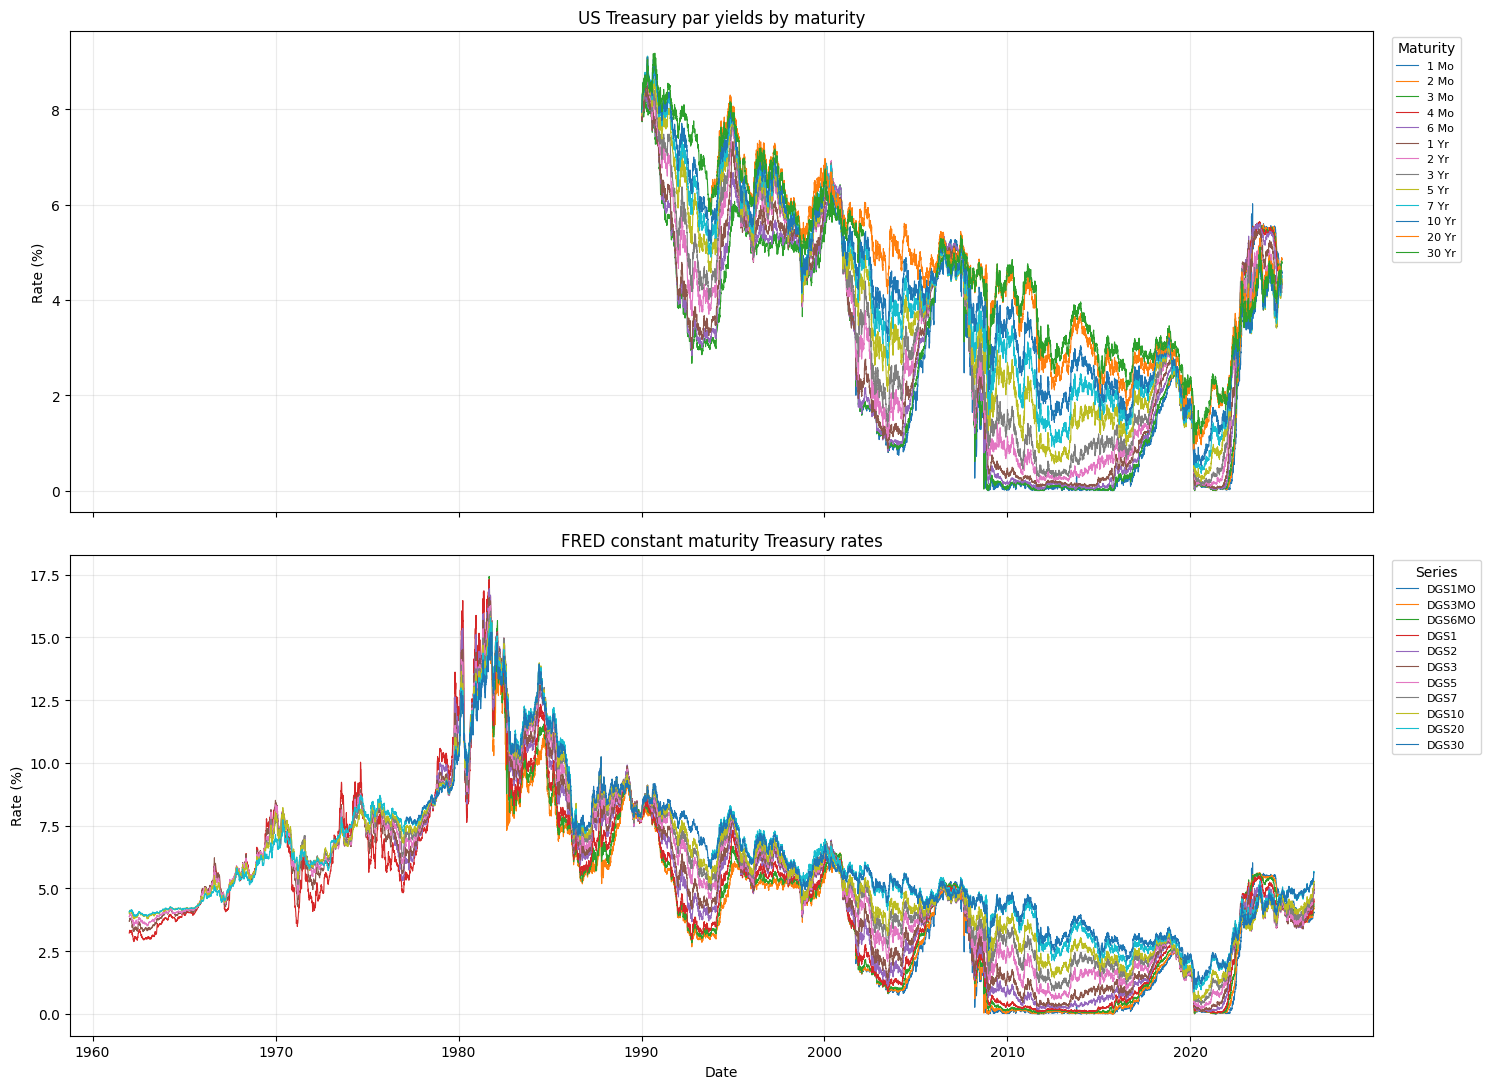

In [14]:
import matplotlib.pyplot as plt


treasury_plot = treasury.assign(rate=pd.to_numeric(treasury["rate"], errors="coerce")).pivot_table(
    index="date", columns="label", values="rate", aggfunc="mean"
).sort_index()
treasury_order = treasury.groupby("label")["maturity"].min().sort_values().index
treasury_plot = treasury_plot.reindex(columns=treasury_order)

fred_plot = fred_curve.assign(rate=pd.to_numeric(fred_curve["rate"], errors="coerce")).pivot_table(
    index="date", columns="series", values="rate", aggfunc="mean"
).sort_index()
fred_order = sorted(FRED_CURVE, key=FRED_CURVE.get)
fred_plot = fred_plot.reindex(columns=fred_order)

fig, axes = plt.subplots(2, 1, figsize=(15, 11), sharex=True)
for label in treasury_plot.columns:
    axes[0].plot(treasury_plot.index, treasury_plot[label], label=label, linewidth=0.8)
axes[0].set_title("US Treasury par yields by maturity")
axes[0].set_ylabel("Rate (%)")
axes[0].legend(title="Maturity", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[0].grid(True, alpha=0.25)

for series in fred_plot.columns:
    axes[1].plot(fred_plot.index, fred_plot[series], label=series, linewidth=0.8)
axes[1].set_title("FRED constant maturity Treasury rates")
axes[1].set_ylabel("Rate (%)")
axes[1].set_xlabel("Date")
axes[1].legend(title="Series", bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
axes[1].grid(True, alpha=0.25)

fig.tight_layout()
plt.show()

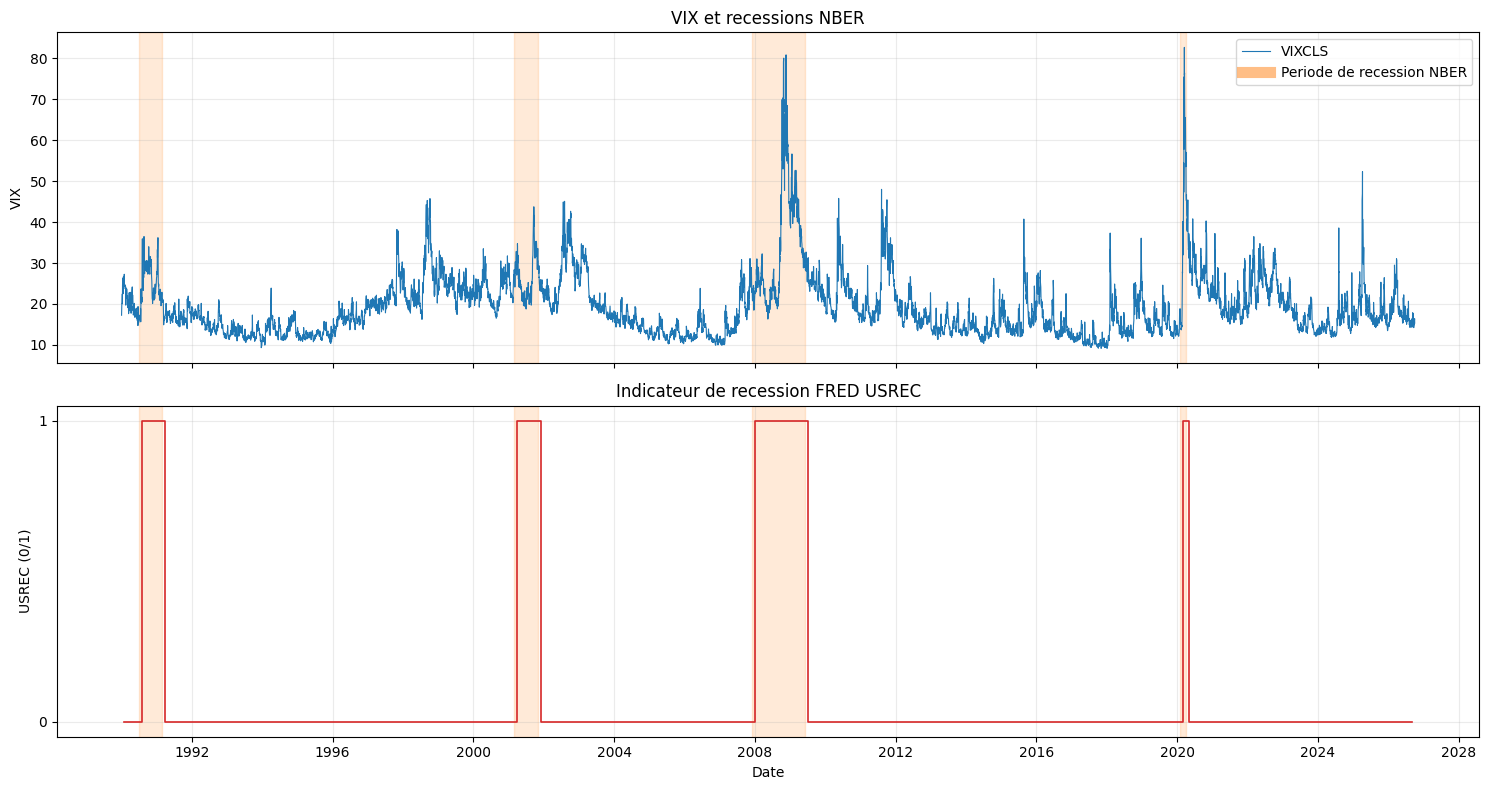

In [16]:
vix_plot = vix.copy()
vix_plot["value"] = pd.to_numeric(vix_plot["value"], errors="coerce")
vix_plot = vix_plot.dropna(subset=["value"]).sort_values("date")

usrec_plot = usrec.copy()
usrec_plot["value"] = pd.to_numeric(usrec_plot["value"], errors="coerce")
usrec_plot = usrec_plot.dropna(subset=["value"]).sort_values("date")

plot_start = vix_plot["date"].min()
plot_end = vix_plot["date"].max()
usrec_plot = usrec_plot.loc[usrec_plot["date"].between(plot_start, plot_end)]
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

axes[0].plot(vix_plot["date"], vix_plot["value"], color="tab:blue", linewidth=0.8, label="VIXCLS")
axes[0].set_title("VIX et recessions NBER")
axes[0].set_ylabel("VIX")
axes[0].grid(True, alpha=0.25)

axes[1].step(usrec_plot["date"], usrec_plot["value"], where="post", color="tab:red", linewidth=1.2)
axes[1].set_title("Indicateur de recession FRED USREC")
axes[1].set_ylabel("USREC (0/1)")
axes[1].set_xlabel("Date")
axes[1].set_yticks([0, 1])
axes[1].grid(True, alpha=0.25)

for _, cycle in nber.iterrows():
    start = max(pd.to_datetime(cycle["peak"]), plot_start)
    end = min(pd.to_datetime(cycle["trough"]), plot_end)
    if start < end:
        for axis in axes:
            axis.axvspan(start, end, color="tab:orange", alpha=0.16)

axes[0].plot([], [], color="tab:orange", alpha=0.5, linewidth=8, label="Periode de recession NBER")
axes[0].legend(loc="upper right")
fig.tight_layout()
plt.show()